# Milestone 6: Predictive Model, a weekly demand forecast
**Customer & Sales Intelligence for Martik Farm Enterprises** | Ephantus Macharia, Lux Dev Academy

**Business question (from the problem statement):** *What demand should we expect next month?* A weekly forecast by product group, so purchasing and production can be planned.
**Success measure set in Milestone 1:** forecast error (WAPE) lower than a naive baseline on a hold-out period.

> The data is **synthetic** (calibrated on Martik Farm's real price list). The method is what is being demonstrated; the numbers describe the simulated business.
> Code: `src/forecast_model.py` (model and evaluation), `src/forecast_figures.py` (figures). Seeded and re-runnable.

**Why a forecast and not churn?** The churn table has only 54 positive cases (5.4% of 995 rows), too few to train and validate a reliable model. The weekly series gives 2,832 forecast rows and many time-ordered test weeks.

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
from IPython.display import Markdown, display, Image
import forecast_model as fm
pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", "{:,.3f}".format)
md = lambda s: display(Markdown(s)); fig = lambda n: display(Image(f"../figures/{n}.png"))
res = fm.run(); d, ev, val, tst, vall, cal = res["d"], res["ev"], res["val"], res["test"], res["val_all"], res["cal"]
cols = res["base_cols"] + ["model", "blend"]

## 1. What is being forecast
- **Target:** units sold per week (billed quantity) for each of **8 product categories**. Grains & Legumes is left out: it is 0.3% of revenue and missing in 7 of 105 weeks.
- **Horizon:** 1, 2, 3 and 4 weeks ahead, made from the last completed week. Four weeks is how far ahead purchasing needs to plan. The two partial end-weeks of the data are dropped, leaving **103 full weeks** (7 Oct 2024 to 21 Sep 2026).
- **Metric:** **WAPE** = total absolute error / total actual demand (lower is better), and **bias** = total (forecast - actual) / total actual (positive = over-forecasting). WAPE is used instead of MAPE because small weeks would dominate MAPE.
- **Forecast unit:** one row per (category, forecast origin, horizon), 2,832 rows (1,200 train, 832 validation, 800 test).

## 2. Time-ordered splits (no leakage)

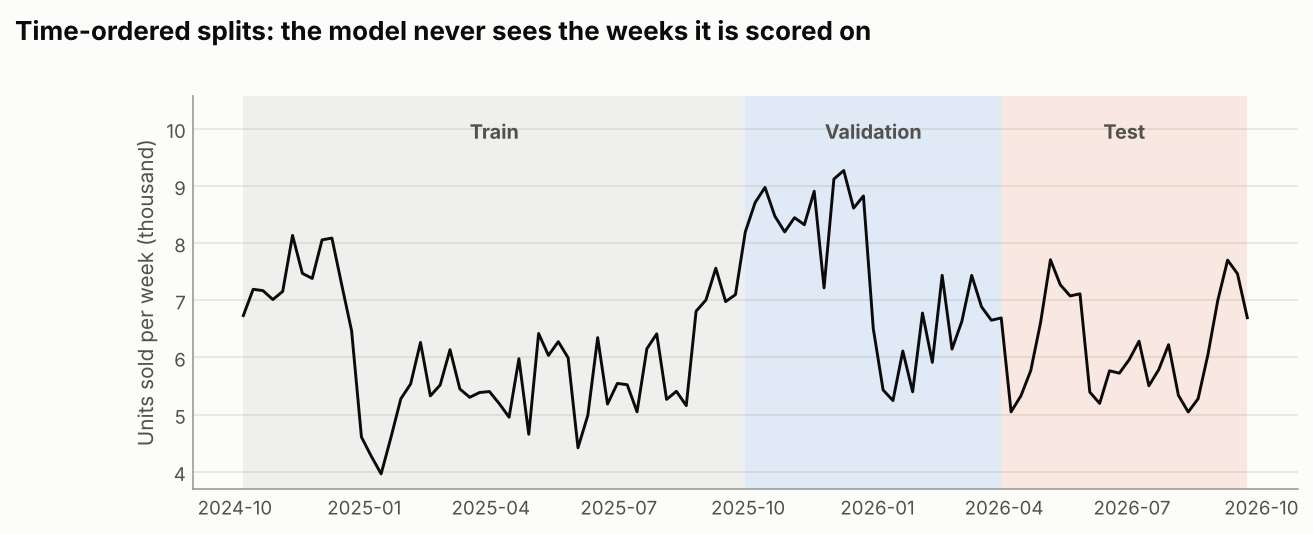

In [2]:
fig("m6_01_splits")

Splits are by **target week**, in time order, never shuffled:

| Split | Target weeks | Used for |
|---|---|---|
| Train | 7 Oct 2024 - 29 Sep 2025 | fitting candidate models |
| Validation | 6 Oct 2025 - 30 Mar 2026 | choosing the model settings and the best baseline |
| Test | 6 Apr - 21 Sep 2026 | scored **once**, with the chosen model refitted on train + validation |

**Leakage controls.** Every feature for a forecast made at week *o* uses only weeks up to *o*. The only information from the future is what a manager genuinely knows in advance: the season label, public holidays and the promotion plan for the target week. Level is measured relative to the last 8 weeks, so no statistic is computed on the whole series.
The churn answer key from the generator is not used anywhere.

## 3. The baselines (what the model has to beat)
| Baseline | Forecast for week *t* made at week *o* | Why it is a fair comparison |
|---|---|---|
| B1 Naive | last week's demand | the simplest possible |
| B2 4-week average | mean of the last 4 weeks | the "simple baseline" named in the problem statement |
| B3 Same week last year | demand 52 weeks before *t* | captures seasonality, ignores growth |
| B4 Last year x growth | B3 multiplied by recent growth (last 8 weeks vs the same 8 weeks a year earlier) | **the strongest simple rule**: seasonality plus growth |

B3 and B4 only exist once there is a year of history (from Oct 2025), which is itself a limitation of a 2-year dataset. **The best baseline was picked on validation, before the test set was scored.**

## 4. The model
**Gradient boosting** (scikit-learn `HistGradientBoostingRegressor`), one model for all 8 categories and 4 horizons. It predicts the **ratio of future demand to the recent level** (mean of the last 8 weeks), so small and large categories share what they learn.
Features: recent level ratios (last week, 4-week, 13-week), horizon, category, the target week's season label, holiday days, week-of-year (sine/cosine), whether a promotion is planned for that category, and the season at the forecast origin.
It deliberately gets **no last-year values**: in the first year they do not exist, so they would be empty throughout training. The model must learn seasonality from the labels, with only one earlier peak to learn from. That choice matters for the results below.

Six settings were compared on **validation only**:

In [3]:
res["selection"][["config", "loss", "max_depth", "learning_rate", "max_iter", "validation_wape"]]

,config,loss,max_depth,learning_rate,max_iter,validation_wape
0,0,squared_error,3,0.050,150,0.147
3,3,absolute_error,3,0.050,150,0.152
4,4,absolute_error,4,0.050,250,0.162
1,1,squared_error,4,0.050,250,0.164
5,5,absolute_error,6,0.030,250,0.171
2,2,squared_error,6,0.030,250,0.183


The simplest, most regularised setting won (shallow trees, squared error). It sits at the edge of the grid, so even simpler might do as well; with only one year of training weeks, more complexity just fits noise.

In [4]:
vb = val
display(Markdown("**Baselines on validation (rows where all four exist):**")); display(res["base_val"])
md(f"**Best baseline chosen on validation: `{res['best_base']}` (last year x growth).**")

**Baselines on validation (rows where all four exist):**

,validation_wape
b1_naive,0.189
b2_avg4,0.185
b3_ly,0.206
b4_ly_growth,0.142


**Best baseline chosen on validation: `b4_ly_growth` (last year x growth).**

## 5. Results
**Comparable rows only:** B3/B4 need a year of history, so the table compares every method on the same rows (validation from Dec 2025: 528 rows; test: 800 rows). This is the fair like-for-like comparison. The peak is checked separately on all validation weeks in section 6.

In [5]:
def tab(part):
    t = fm.score_table(part, cols).set_index("method")
    t["wape_%"] = 100 * t.wape; t["bias_%"] = 100 * t.bias
    t["total_level_wape_%"] = [100 * fm.total_wape(part, c) for c in t.index]
    return t[["rows", "wape_%", "bias_%", "total_level_wape_%"]]
display(Markdown("**VALIDATION** (model trained on train only)")); display(tab(val))
display(Markdown("**TEST** (model refitted on train + validation, scored once)")); tab_test = tab(tst); display(tab_test)

**VALIDATION** (model trained on train only)

,rows,wape_%,bias_%,total_level_wape_%
method,,,,
b1_naive,528,18.859,3.467,16.068
b2_avg4,528,18.460,5.857,16.023
b3_ly,528,20.592,-18.338,18.964
b4_ly_growth,528,14.241,-2.837,11.050
model,528,14.095,-1.567,12.186
blend,528,12.027,-2.202,9.897


**TEST** (model refitted on train + validation, scored once)

,rows,wape_%,bias_%,total_level_wape_%
method,,,,
b1_naive,800,17.698,-0.592,15.151
b2_avg4,800,17.330,-0.406,15.674
b3_ly,800,12.659,-5.140,9.052
b4_ly_growth,800,13.085,5.255,8.596
model,800,12.160,6.009,9.842
blend,800,11.973,5.632,9.018


*Total-level WAPE* sums the 8 categories first and then measures the error of the weekly total, which is smaller because errors in different categories partly cancel. `blend` is a 50/50 average of the model and B4 (see section 6 for why it was added).

In [6]:
rows = []
for a, b in [("model", "b2_avg4"), ("model", "b4_ly_growth"), ("blend", "b4_ly_growth"), ("blend", "b2_avg4")]:
    lo, hi = fm.block_bootstrap_diff(tst, a, b)
    rows.append(dict(comparison=f"{a} minus {b}", wape_difference_pts=100 * (fm.wape(tst.actual, tst[a]) - fm.wape(tst.actual, tst[b])), ci_low_pts=100 * lo, ci_high_pts=100 * hi,
                     verdict="clearly better" if hi < 0 else ("clearly worse" if lo > 0 else "not distinguishable")))
cmp_ = pd.DataFrame(rows); cmp_

,comparison,wape_difference_pts,ci_low_pts,ci_high_pts,verdict
0,model minus b2_avg4,-5.170,-9.214,-0.802,clearly better
1,model minus b4_ly_growth,-0.926,-2.324,0.521,not distinguishable
2,blend minus b4_ly_growth,-1.113,-1.875,-0.352,clearly better
3,blend minus b2_avg4,-5.357,-9.064,-1.087,clearly better


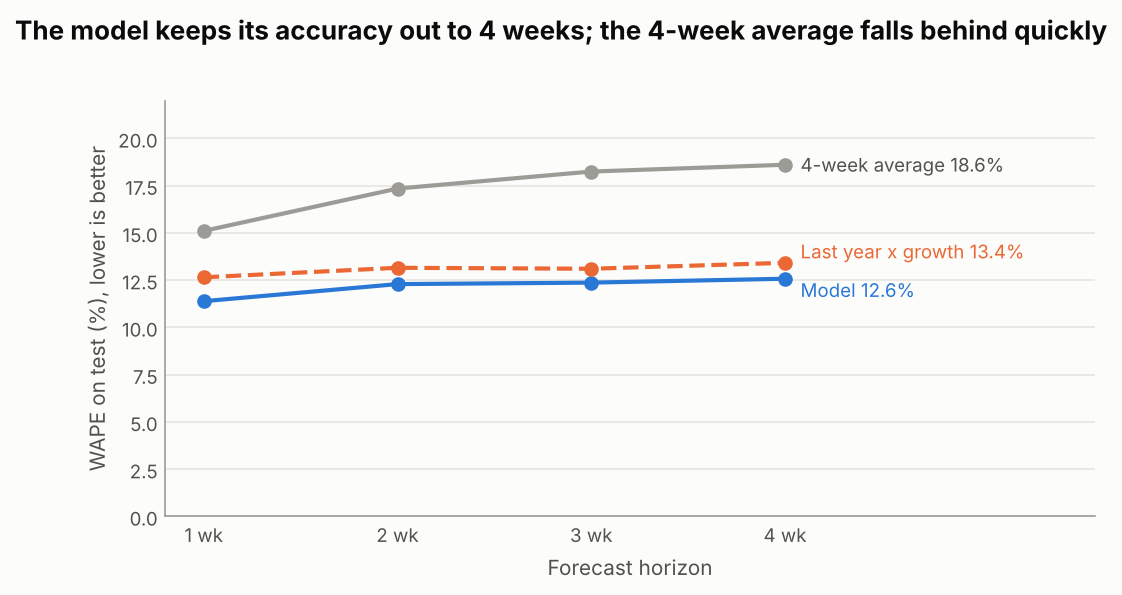

In [7]:
fig("m6_03_by_horizon")

In [8]:
t = tab_test
md("### Comparison with the baseline (plain language)")
md(f"""
- **Against the baseline named in the problem statement (4-week average): clearly better.** On the test weeks the model's error is {t.loc['model','wape_%']:.1f}% against {t.loc['b2_avg4','wape_%']:.1f}% for the 4-week average, about **{100*(1-t.loc['model','wape_%']/t.loc['b2_avg4','wape_%']):.0f}% less error** (95% interval for the difference {cmp_.iloc[0].ci_low_pts:.1f} to {cmp_.iloc[0].ci_high_pts:.1f} points of WAPE). The success measure from Milestone 1 is met.
- **Against the strongest simple rule (last year x growth): about the same.** {t.loc['model','wape_%']:.1f}% vs {t.loc['b4_ly_growth','wape_%']:.1f}%, a gap of {abs(cmp_.iloc[1].wape_difference_pts):.1f} points whose interval ({cmp_.iloc[1].ci_low_pts:.1f} to {cmp_.iloc[1].ci_high_pts:+.1f}) includes zero. **I cannot claim the model is better than that rule.** At the total level the rule is actually slightly better ({t.loc['b4_ly_growth','total_level_wape_%']:.1f}% vs {t.loc['model','total_level_wape_%']:.1f}%).
- **What the model adds over that rule:** it works from the first year of data (the rule needs 59 weeks of history), and it is better than the rule in non-peak weeks and in 4 of the 8 categories (Vegetables, Herbs, Alliums, Leafy Greens), but worse for Potato Products, Roots & Tubers and Peppers. What it lacks is a last-year memory, which is why it fails in the peak (next section).
- **Accuracy holds out to 4 weeks** ({fm.wape(tst[tst.h==1].actual, tst[tst.h==1].model)*100:.1f}% at 1 week, {fm.wape(tst[tst.h==4].actual, tst[tst.h==4].model)*100:.1f}% at 4 weeks), while the 4-week average gets worse with distance.
""")

### Comparison with the baseline (plain language)


- **Against the baseline named in the problem statement (4-week average): clearly better.** On the test weeks the model's error is 12.2% against 17.3% for the 4-week average, about **30% less error** (95% interval for the difference -9.2 to -0.8 points of WAPE). The success measure from Milestone 1 is met.
- **Against the strongest simple rule (last year x growth): about the same.** 12.2% vs 13.1%, a gap of 0.9 points whose interval (-2.3 to +0.5) includes zero. **I cannot claim the model is better than that rule.** At the total level the rule is actually slightly better (8.6% vs 9.8%).
- **What the model adds over that rule:** it works from the first year of data (the rule needs 59 weeks of history), and it is better than the rule in non-peak weeks and in 4 of the 8 categories (Vegetables, Herbs, Alliums, Leafy Greens), but worse for Potato Products, Roots & Tubers and Peppers. What it lacks is a last-year memory, which is why it fails in the peak (next section).
- **Accuracy holds out to 4 weeks** (11.4% at 1 week, 12.6% at 4 weeks), while the 4-week average gets worse with distance.


## 6. What the model gets wrong
### 6a. It misses the peak
The comparison above covers a test period (Apr-Sep 2026) with **no peak season**, and the comparable validation rows start in Dec 2025, so they miss most of the Oct-Dec 2025 peak. To check the peak properly I scored every validation week, using only the baselines that always exist:

In [9]:
va = vall.copy(); va["season"] = va.target_week.map(cal.season)
rows = []
for s, g in [("All validation weeks", va)] + [(f"{k} season", g) for k, g in va.groupby("season")]:
    rows.append({"weeks": s, "n_weeks": g.target_week.nunique(), "model_wape_%": 100 * fm.wape(g.actual, g.model), "model_bias_%": 100 * fm.bias(g.actual, g.model),
                 "4wk_avg_wape_%": 100 * fm.wape(g.actual, g.b2_avg4), "naive_wape_%": 100 * fm.wape(g.actual, g.b1_naive)})
peak_tbl = pd.DataFrame(rows).set_index("weeks"); peak_tbl

,n_weeks,model_wape_%,model_bias_%,4wk_avg_wape_%,naive_wape_%
weeks,,,,,
All validation weeks,26,14.710,-6.322,15.746,16.131
Low season,4,16.101,10.805,42.965,31.703
Normal season,9,10.941,0.729,11.473,14.139
Peak season,13,16.511,-13.687,12.596,14.080


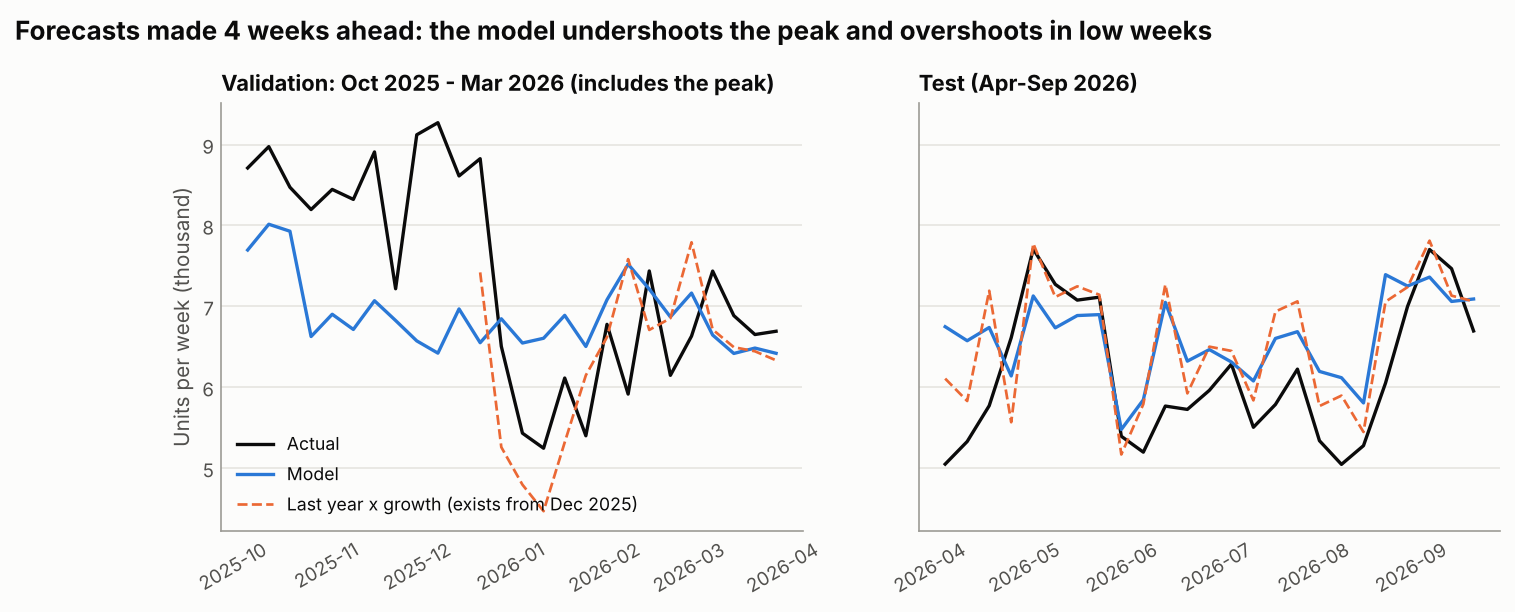

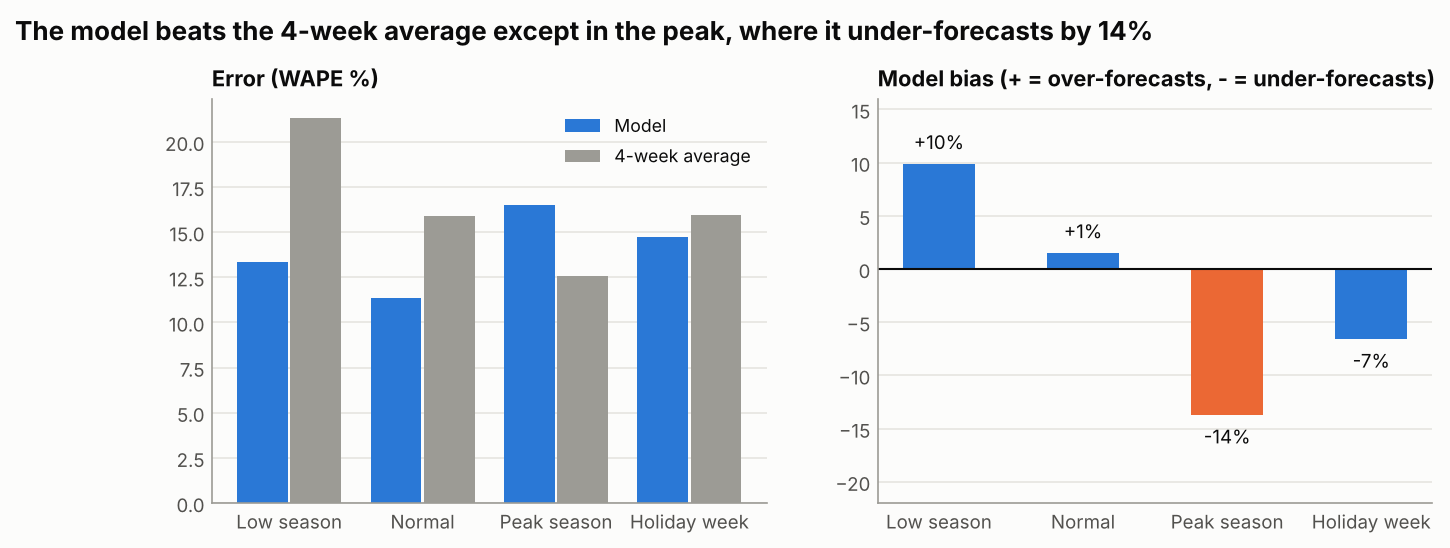

In [10]:
fig("m6_02_actual_vs_forecast"); fig("m6_05_error_by_week_type")

In [11]:
p = peak_tbl.loc["Peak season"]
md(f"""
**In the peak the model is worse than the plain 4-week average** ({p['model_wape_%']:.1f}% vs {p['4wk_avg_wape_%']:.1f}% error) and **under-forecasts by {abs(p['model_bias_%']):.0f}%**. After the first weeks of October the blue line in the left chart stays at about 6,500-7,000 units a week while actual demand ran at 7,200-9,300.
**Why:** it had seen exactly one peak (Oct-Dec 2024) and had no last-year values, so it learned "peak weeks are somewhat higher" but not how high, and the business grew about 17% between the two years. The gap widens with horizon (under-forecast of 11% one week ahead, 17% four weeks ahead).
**What I did about it:** a 50/50 **blend of the model and the last-year rule** was added as a candidate after seeing this on validation. It is better than either alone on validation ({100*fm.wape(val.actual, val.blend):.1f}% vs {100*fm.wape(val.actual, val.model):.1f}% and {100*fm.wape(val.actual, val.b4_ly_growth):.1f}%) and on the untouched test weeks it scores {100*fm.wape(tst.actual, tst.blend):.1f}%, the best of all methods, **{abs(cmp_.iloc[2].wape_difference_pts):.1f} points better than last year x growth** (interval {cmp_.iloc[2].ci_low_pts:.1f} to {cmp_.iloc[2].ci_high_pts:.1f}). The blend was chosen after looking at validation (and the test period has no peak), so I treat it as a practical safeguard rather than proof it is best in the peak.
""")


**In the peak the model is worse than the plain 4-week average** (16.5% vs 12.6% error) and **under-forecasts by 14%**. After the first weeks of October the blue line in the left chart stays at about 6,500-7,000 units a week while actual demand ran at 7,200-9,300.
**Why:** it had seen exactly one peak (Oct-Dec 2024) and had no last-year values, so it learned "peak weeks are somewhat higher" but not how high, and the business grew about 17% between the two years. The gap widens with horizon (under-forecast of 11% one week ahead, 17% four weeks ahead).
**What I did about it:** a 50/50 **blend of the model and the last-year rule** was added as a candidate after seeing this on validation. It is better than either alone on validation (12.0% vs 14.1% and 14.2%) and on the untouched test weeks it scores 12.0%, the best of all methods, **1.1 points better than last year x growth** (interval -1.9 to -0.4). The blend was chosen after looking at validation (and the test period has no peak), so I treat it as a practical safeguard rather than proof it is best in the peak.


### 6b. Weak categories, weak weeks

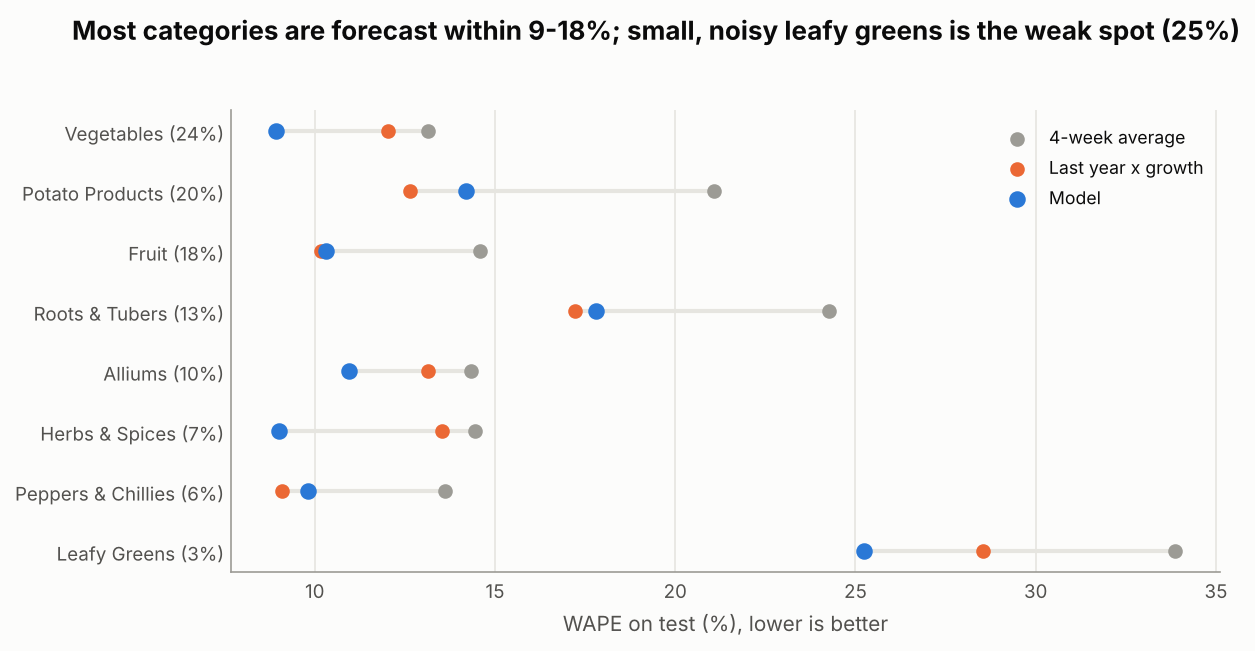

In [12]:
fig("m6_04_by_category")

In [13]:
rows = []
for c, g in tst.groupby("category"):
    rows.append(dict(category=c, share_of_demand_pct=100 * g.actual.sum() / tst.actual.sum(), model_wape_pct=100 * fm.wape(g.actual, g.model), baseline_B4_pct=100 * fm.wape(g.actual, g.b4_ly_growth),
                     avg4_pct=100 * fm.wape(g.actual, g.b2_avg4), model_bias_pct=100 * fm.bias(g.actual, g.model)))
display(pd.DataFrame(rows).sort_values("share_of_demand_pct", ascending=False).set_index("category"))
w = tst[tst.h == 4].groupby("target_week").agg(actual=("actual", "sum"), model=("model", "sum"), last_year_x_growth=("b4_ly_growth", "sum"), avg4=("b2_avg4", "sum"))
w["model_error_%"] = 100 * (w.model / w.actual - 1); w["holiday_days"] = w.index.map(cal.holiday_days)
display(Markdown("**The 6 worst weeks on test (total demand, forecast made 4 weeks earlier):**"))
display(w.reindex(w["model_error_%"].abs().sort_values(ascending=False).index).head(6).round(1))

,share_of_demand_pct,model_wape_pct,baseline_B4_pct,avg4_pct,model_bias_pct
category,,,,,
Vegetables,24.156,8.934,12.032,13.145,2.856
Potato Products,19.656,14.189,12.633,21.075,10.592
Fruit,17.601,10.311,10.176,14.572,5.749
Roots & Tubers,13.453,17.798,17.208,24.268,9.326
Alliums,9.535,10.962,13.128,14.337,3.965
Herbs & Spices,6.954,8.997,13.541,14.439,2.068
Peppers & Chillies,5.511,9.819,9.099,13.609,2.085
Leafy Greens,3.135,25.241,28.539,33.854,10.647


**The 6 worst weeks on test (total demand, forecast made 4 weeks earlier):**

,actual,model,last_year_x_growth,avg4,model_error_%,holiday_days
target_week,,,,,,
2026-04-06,"5,048.500","6,747.800","6,105.900","6,912.600",33.700,1
2026-04-13,"5,328.000","6,574.400","5,828.900","6,774.600",23.400,0
2026-06-15,"5,766.500","7,048.800","7,269.800","7,167.500",22.200,0
2026-08-24,"6,050.500","7,391.300","7,057.100","5,949.400",22.200,0
2026-08-10,"5,045.500","6,117.100","5,895.800","5,868.600",21.200,0
2026-04-20,"5,770.500","6,738.200","7,192.600","6,900.800",16.800,0


In [14]:
md("**What drives the model (permutation importance on validation: how much the error grows when a feature is scrambled):**"); display(res["importance"].head(8).to_frame("importance"))

**What drives the model (permutation importance on validation: how much the error grows when a feature is scrambled):**

,importance
t_sin,0.034
t_cos,0.012
t_low,0.009
last_r,0.007
cat,0.004
mean4_r,0.002
t_hol,0.001
scale,0.000


- **Leafy greens** (3% of demand) is the worst category at about 25% error: small volumes with random swings. It matters little for purchasing, so I would accept that.
- **Roots & Tubers and Potato Products** have higher error (14-18%) and the model over-forecasts them by about 9-11%.
- **Low-season and holiday weeks are over-forecast.** In the test period the model forecasts about 6% too much overall (bias in the table above). The worst test weeks are 6 and 13 April, right after Easter (Good Friday 3 April), when actual demand fell to about 5,000 units and the model expected 6,600-6,700. The model only knows *how many holiday days* a week has, not that Easter is followed by a slow week.
- **Week-of-year and season matter most** (permutation importance); last week's level matters less than a human would expect, because the model is mostly reading the calendar.

## 7. Forecast for the next 4 weeks (Oct 2026, the start of the peak)

,recommended (blend),model alone,4-week average,last year x growth,80% low,80% high
target_week,,,,,,
2026-09-28,"8,098.000","8,113.000","7,215.000","8,082.000","6,406.000","9,598.000"
2026-10-05,"8,482.000","8,376.000","7,215.000","8,587.000","6,709.000","10,053.000"
2026-10-12,"8,647.000","8,441.000","7,215.000","8,854.000","6,840.000","10,249.000"
2026-10-19,"8,307.000","8,233.000","7,215.000","8,381.000","6,571.000","9,846.000"


**By category (recommended forecast, units per week):**

target_week,2026-09-28,2026-10-05,2026-10-12,2026-10-19
category,,,,
Alliums,777.000,802.000,828.000,741.000
Fruit,"1,421.000","1,506.000","1,471.000","1,417.000"
Herbs & Spices,554.000,594.000,558.000,569.000
Leafy Greens,258.000,244.000,248.000,268.000
Peppers & Chillies,444.000,460.000,473.000,463.000
Potato Products,"1,543.000","1,731.000","1,885.000","1,803.000"
Roots & Tubers,"1,028.000","1,092.000","1,079.000",954.000
Vegetables,"2,072.000","2,053.000","2,105.000","2,092.000"


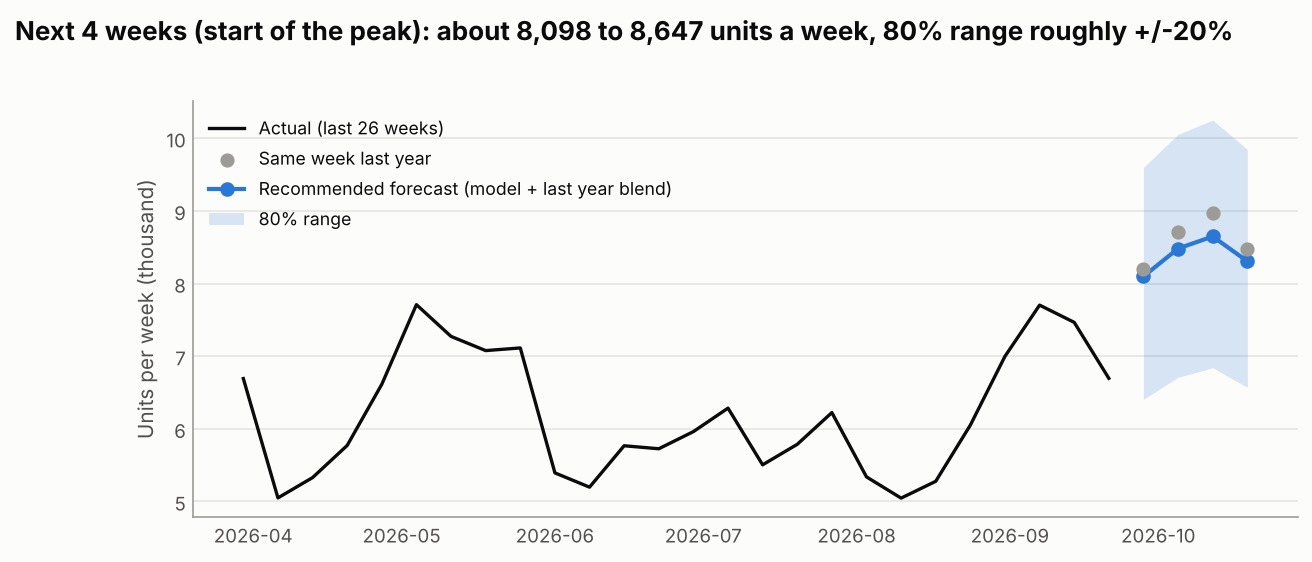

In [15]:
nf, (qlo, qhi) = fm.next_four_weeks(res)
tot = nf.groupby("target_week")[["forecast", "model_only", "baseline_avg4", "baseline_last_year_x_growth", "low80", "high80"]].sum().round(0)
tot.columns = ["recommended (blend)", "model alone", "4-week average", "last year x growth", "80% low", "80% high"]
display(tot)
display(Markdown("**By category (recommended forecast, units per week):**"))
display(nf.pivot(index="category", columns="target_week", values="forecast").round(0))
fig("m6_06_next_4_weeks")

**How to use it.** The recommended forecast is the 50/50 blend, because the model alone is weakest exactly in this period. For Oct 2026 the model alone is a little lower than last year x growth in the second and third weeks; plan stock for the blend and treat the upper end of the 80% range as the case to be ready for.
The 80% range comes from how far past blend forecasts missed (actual between about 0.8 and 1.2 times the forecast), so expect roughly one week in five to fall outside it.
**Assumption:** the calendar for these weeks (season label, holidays) was copied from the same weeks a year earlier; public-holiday dates for Oct 2026 should be checked against the official calendar.

## 8. Conclusions and limits
1. **The model beats the problem statement's baseline (4-week average) by about 30% in error** and holds up to 4 weeks ahead. **It does not beat "last year x growth" in a way that can be told apart from chance.** The honest summary is: a simple seasonal rule is hard to beat with two years of data.
2. **The model's known failure is the peak:** it under-forecast the Oct-Dec 2025 peak by about 14% and was worse than the 4-week average there. The blend is the safeguard; the test period had no peak, so the blend's peak behaviour is **unverified**.
3. **Easter and other holiday weeks** are mis-forecast because the model has no holiday-aftermath features.
4. **Data limits:** 2 years, 2 peaks, synthetic data. A model with one year of training cannot be expected to learn seasonality well; with a third year the last-year features could be used in training and I expect the peak error to fall.
5. **Not done:** prediction by individual product, price effects (revenue forecast), and the churn model.
6. **Checks:** every split is time-ordered; model settings and the best baseline were chosen on validation; the test set was scored once; intervals use block bootstrap by 4-week blocks; the notebook re-runs from the cleaned data.